# PyTorch MNIST Example

Hyperparameters:

In [19]:
SEED = 0
BATCH_SIZE = 128
LEARNING_RATE = 0.001
NUM_EPOCHS = 100
EARLY_STOPPING_PATIENCE = 10
WARMUP_EPOCHS = 5

Import some packages and set device variable

In [20]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets


# Set random seed
torch.manual_seed(SEED)

# Set device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


## Load and process dataset

In [21]:
train_mnist = datasets.MNIST(root='/mnist_data', train=True, download=True)
test_mnist = datasets.MNIST(root='/mnist_data', train=False, download=True)

# Initialize and normalize training and test data
x_train = train_mnist.data / 255.0
x_test = test_mnist.data / 255.0 

# Get training data labels
y_train = train_mnist.targets
y_test = test_mnist.targets

# Normalize images to have zero mean and unit variance
mean = x_train.mean()
std = x_train.std()
x_train = (x_train - mean) / std # Normalize training data
x_test = (x_test - mean) / std # Normalize test data

print(f"Training data shape: {x_train.shape}")
print(f"Test data shape: {x_test.shape}")
print(f"Mean: {mean}, Std: {std}")

Training data shape: torch.Size([60000, 28, 28])
Test data shape: torch.Size([10000, 28, 28])
Mean: 0.13066048920154572, Std: 0.30810782313346863


Tensor dataset and Data Loader setup data for our convenience

In [22]:
train_dataset = TensorDataset(x_train, y_train)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)

test_dataset = TensorDataset(x_test, y_test)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

## Model Architecture

In [23]:

class CNN(nn.Module):
    def __init__(self):
        super(CNN, self).__init__()
        self.conv_layers = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, stride=1, padding=1), 
            nn.BatchNorm2d(32),
            nn.ReLU(),
            
            nn.Conv2d(32, 32, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2), # 28 x 28 -> 14 x 14
            
            nn.Dropout(0.10),
            
            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            
            nn.Conv2d(64, 64, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2), # 14 x 14 -> 7 x 7
            
            nn.Dropout(0.15)
        )
        
        self.fc_layers = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(0.30),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        x = self.conv_layers(x)
        # x = x.view(x.size(0), -1)  # Flatten the tensor
        # x = x.flatten(start_dim=1)  # Flatten the tensor
        x = self.fc_layers(x)
        return x

## Setup for Training

Create object for recording loss

In [24]:
from matplotlib import pyplot as plt

class LossHistory:
    def __init__(self):
        self.train_losses = []
        self.val_losses = []
        self.best_val_loss = float('inf')
        self.early_stopping_counter = 0
        self.improvement_flag = False
        self.epoch = 0

    def update(self, train_loss, val_loss):
        self.train_losses.append(train_loss)
        self.val_losses.append(val_loss)
        self.epoch += 1

        if val_loss < self.best_val_loss:
            self.best_val_loss = val_loss
            self.improvement_flag = True
            self.early_stopping_counter = 0
        else:
            self.improvement_flag = False
            self.early_stopping_counter += 1
            
    def improvement(self):
        return self.improvement_flag

    def should_stop_early(self):
        return self.early_stopping_counter >= EARLY_STOPPING_PATIENCE and self.epoch > WARMUP_EPOCHS
    
    def plot(self):
        plt.figure(figsize=(10, 5))
        plt.plot(self.train_losses, label='Training Loss')
        plt.plot(self.val_losses, label='Validation Loss')
        plt.axvline(x=WARMUP_EPOCHS, color='r', linestyle='--', label='Warmup Epochs')
        plt.axvline(x=self.epoch - EARLY_STOPPING_PATIENCE, color='g', linestyle='--', label='Save Best Model Epoch')
        plt.xlabel('Epochs')
        plt.ylabel('Loss')
        plt.title('Training and Validation Loss Over Epochs')
        plt.legend()
        plt.grid()
        plt.show()

Create Model

In [25]:
model = CNN().to(device)
print(f"Total number of parameters: {sum(param.numel() for param in model.parameters())}")
print(f"Total number of trainable parameters: {sum(param.numel() for param in model.parameters() if param.requires_grad)}")
print(f"Model architecture:\n{model}")

Total number of parameters: 468010
Total number of trainable parameters: 468010
Model architecture:
CNN(
  (conv_layers): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Dropout(p=0.1, inplace=False)
    (7): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (9): ReLU()
    (10): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU()
    (12): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (13): Dropout(p=0.15, inplace=False)
  )
  (fc_layers): Sequential(
    (0): Flatten(star

Setup criterion and optimizer

In [26]:
loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

Setup Trainer

In [27]:
def train_epoch(model, data_loader, loss_function, optimizer, device):
    # Set the model to training mode (this is important for layers like dropout and batch normalization)
    model.train()
    
    total_loss = 0
    for images, labels in data_loader:
        # Move images and labels to the specified device (this can be done before the loop to avoid repeated calls)
        images, labels = images.to(device), labels.to(device) # Repeated call is useful for multi-GPU training
        
        # Zero the gradients before running the backward pass
        optimizer.zero_grad()
        outputs = model(images.unsqueeze(1).float())  # Add channel dimension (B, 28, 28) -> (B, 1, 28, 28) and convert to float
        
        loss = loss_function(outputs, labels)
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item() * images.size(0)
    return total_loss / len(data_loader.dataset)


def predict(model, data_loader, device):
    model.eval()
    all_predictions = []
    with torch.no_grad():
        for images, _ in data_loader:
            images = images.to(device)
            outputs = model(images.unsqueeze(1).float())
            _, predicted = torch.max(outputs.data, 1)
            all_predictions.extend(predicted.cpu().numpy())
    return all_predictions


def evaluate(model, data_loader, loss_function, device):
    # Set the model to evaluation mode (this is important for layers like dropout and batch normalization)
    model.eval()
    
    total_loss = 0
    with torch.no_grad():  # Disable gradient calculation for evaluation
        for images, labels in data_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images.unsqueeze(1).float())  # Add channel dimension and convert to float
            
            loss = loss_function(outputs, labels)
            total_loss += loss.item() * images.size(0)
    return total_loss / len(data_loader.dataset)


def train(model, train_loader, test_loader, loss_function, optimizer, device, num_epochs):
    history = LossHistory()
    
    for epoch in range(num_epochs):
        train_loss = train_epoch(model, train_loader, loss_function, optimizer, device)
        val_loss = evaluate(model, test_loader, loss_function, device)
        
        history.update(train_loss, val_loss)
        
        print(f"Epoch [{epoch+1}/{num_epochs}], Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}")
        
        if history.improvement():
            # Save the model checkpoint if validation loss improved
            torch.save(model.state_dict(), 'best_model.pth')
        
        if history.should_stop_early():
            print(f"Early stopping triggered at epoch {epoch+1}.")
            break
        
    # Load the best model weights after training
    model.load_state_dict(torch.load('best_model.pth'))
            
    return history

## Traing Model

In [28]:
train_args = {
    "model": model,
    "train_loader": train_loader,
    "test_loader": test_loader,
    "loss_function": loss_function,
    "optimizer": optimizer,
    "device": device,
    "num_epochs": NUM_EPOCHS
}

history = train(**train_args)

Epoch [1/100], Train Loss: 0.1623, Val Loss: 0.0361
Epoch [2/100], Train Loss: 0.0524, Val Loss: 0.0254
Epoch [3/100], Train Loss: 0.0394, Val Loss: 0.0267
Epoch [4/100], Train Loss: 0.0320, Val Loss: 0.0182
Epoch [5/100], Train Loss: 0.0301, Val Loss: 0.0193
Epoch [6/100], Train Loss: 0.0243, Val Loss: 0.0195
Epoch [7/100], Train Loss: 0.0236, Val Loss: 0.0226
Epoch [8/100], Train Loss: 0.0190, Val Loss: 0.0196
Epoch [9/100], Train Loss: 0.0186, Val Loss: 0.0228
Epoch [10/100], Train Loss: 0.0168, Val Loss: 0.0199
Epoch [11/100], Train Loss: 0.0163, Val Loss: 0.0168
Epoch [12/100], Train Loss: 0.0136, Val Loss: 0.0190
Epoch [13/100], Train Loss: 0.0126, Val Loss: 0.0201
Epoch [14/100], Train Loss: 0.0135, Val Loss: 0.0205
Epoch [15/100], Train Loss: 0.0119, Val Loss: 0.0202
Epoch [16/100], Train Loss: 0.0104, Val Loss: 0.0248
Epoch [17/100], Train Loss: 0.0123, Val Loss: 0.0215
Epoch [18/100], Train Loss: 0.0097, Val Loss: 0.0194
Epoch [19/100], Train Loss: 0.0122, Val Loss: 0.0225
Ep

## Evaluate Training Performance

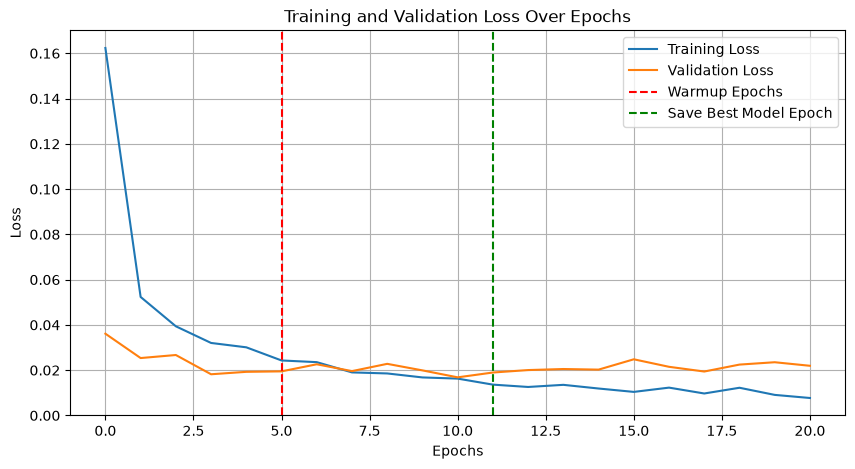

In [29]:
history.plot()

## Evaluate Model Results

Test Loss: 0.0168


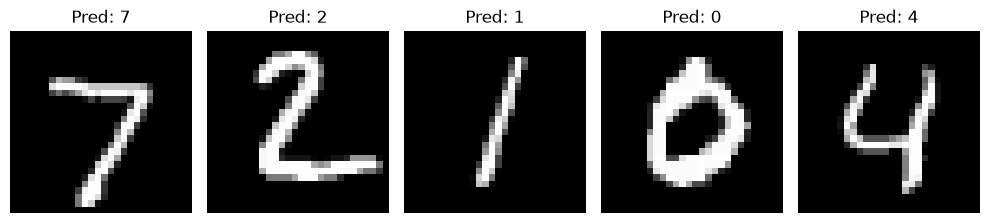

In [30]:
# Evaluate the model on the test set
test_loss = evaluate(model, test_loader, loss_function, device)
print(f"Test Loss: {test_loss:.4f}")

# Plot predictions for a few test images
import matplotlib.pyplot as plt

predictions = predict(model, test_loader, device)

plot_count = 5
plt.figure(figsize=(10, 5))
for i in range(plot_count):
    plt.subplot(1, plot_count, i + 1)
    plt.imshow(x_test[i], cmap='gray')
    plt.title(f"Pred: {predictions[i]}")
    plt.axis('off')
    plt.tight_layout()
    

Plot Confusion Matrix

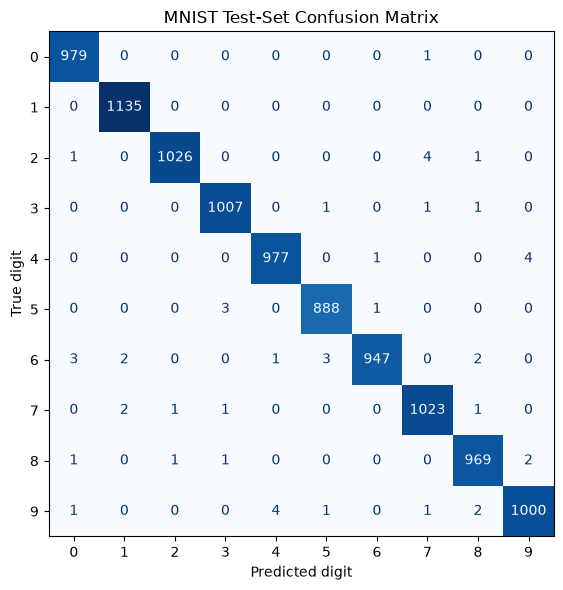

In [31]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

true_labels = y_test.cpu().numpy()
cm = confusion_matrix(true_labels, predictions)

fig, ax = plt.subplots(figsize=(7, 6))
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=range(10)
)
display.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")

ax.set_title("MNIST Test-Set Confusion Matrix")
ax.set_xlabel("Predicted digit")
ax.set_ylabel("True digit")
plt.tight_layout()
plt.show()

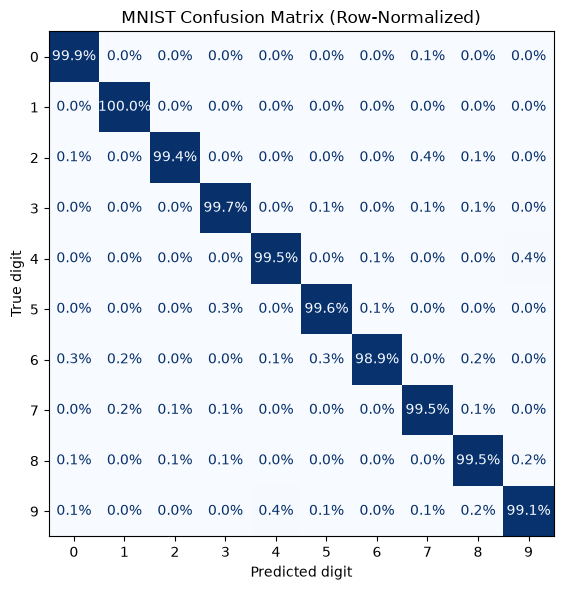

In [32]:
cm_norm = confusion_matrix(
    true_labels, predictions, normalize="true"
)

fig, ax = plt.subplots(figsize=(7, 6))
display = ConfusionMatrixDisplay(
    confusion_matrix=cm_norm,
    display_labels=range(10)
)
display.plot(
    ax=ax, cmap="Blues", colorbar=False,
    values_format=".1%"
)

ax.set_title("MNIST Confusion Matrix (Row-Normalized)")
ax.set_xlabel("Predicted digit")
ax.set_ylabel("True digit")
plt.tight_layout()
plt.show()